# Bluesky scans of MDT X/Y, KCube, and Basler camera

Run this notebook from its directory with the intended Windows hardware attached. Install dependencies into this kernel with `%pip install ophyd bluesky pylablib pypylon numpy` and restart the kernel if needed. The wrapper uses the local `piezo_control.py` SDK, pylablib Kinesis, and pypylon. No stage is homed automatically. Check serial numbers, piezo voltage ceiling, stage homing, stage travel limits, and mechanical clearance **before** allowing any move. Close competing hardware control programs. Images are stored in notebook kernel memory (not persisted); large camera frames can use significant RAM.

In [1]:
import threading
from bluesky import RunEngine
from bluesky import plans as bp
from pylablib.devices import Thorlabs
from piezo_control import PiezoController
from blop_optics import PiezoAxis, KCubeAxis, BaslerCamera

RE = RunEngine({})
# Capture data in RAM for this small demonstration (including full image arrays).
images = []
def collect_image(name, doc):
    if name == 'event':
        images.append(doc['data'].copy())
RE.subscribe(collect_image)
print('MDT devices:', PiezoController.list_devices())
print('Kinesis devices:', Thorlabs.list_kinesis_devices())

MDT devices: [('2202284640-4', '1313&1004&MDT694B&Thorlabs  Inc.&COM5&COM'), ('2202284640-6', '1313&1004&MDT694B&Thorlabs  Inc.&COM4&COM')]
Kinesis devices: [('27006231', 'Brushed Motor Controller')]


## Confirm configuration before opening devices

Fill in the **verified** MDT serial and the attached linear stage's safe absolute travel limits (mm). The KCube serial and camera IP below were observed in earlier notebook tests, but must be checked against the actual hardware. The configured limits are software checks, **not** a substitute for hardware limit switches.

In [2]:
piezo_serial   = "2202284640-4"  # e.g. the verified serial from the MDT discovery list
piezo_serial_2 = "2202284640-6"

kcube_serial = '27006231'  # Confirm on the KCube label
camera_ip = '192.168.10.212'  # Confirm intended camera
stage_limits_mm = (0, 30)  # (minimum_mm, maximum_mm) from the stage's specs and setup

if piezo_serial is None or stage_limits_mm is None:
    raise ValueError('Set verified piezo_serial and stage_limits_mm before connecting')
if piezo_serial not in [sn for sn, _ in PiezoController.list_devices()]:
    raise RuntimeError('Configured MDT serial not found')
if kcube_serial not in [str(sn) for sn, _ in Thorlabs.list_kinesis_devices()]:
    raise RuntimeError('Configured KCube serial not found')

In [3]:
piezo_driver = PiezoController(piezo_serial)
piezo_driver_2 = PiezoController(piezo_serial_2)
motor_driver = None
camera = None
try:
    piezo_driver.open()
    motor_driver = Thorlabs.KinesisMotor(kcube_serial, scale='stage')
    motor = KCubeAxis(motor_driver, name='motor_mm', limits_mm=stage_limits_mm)
    axis_lock = threading.RLock()
    piezo_x = PiezoAxis(piezo_driver, 'X', name='piezo_x_v', lock=axis_lock)
    #piezo_y = PiezoAxis(piezo_driver_2, 'X', name='piezo_y_v', lock=axis_lock)
    camera = BaslerCamera(camera_ip, name='basler_image')
except BaseException:
    if camera is not None:
        camera.close()
    if motor_driver is not None:
        motor_driver.close()
    piezo_driver.close()
    raise

for axis in (piezo_x,  motor):
    print(axis.name, axis.read()[axis.name]['value'], axis.describe()[axis.name]['units'])
print('Detected stage:', motor_driver.get_stage())

piezo_x_v 0.0 V
motor_mm 26.838852611940297 mm
Detected stage: MTS50-Z8


## Preview the three independent scans

Each scan takes 3 images, at the current value, +0.5 and +1 V or mm. `rel_scan` restores the original value afterward, including on interruption if the hardware remains responsive. Do not execute motion cells until the preview matches safe travel and the stage is homed. If a driver fails, inspect the hardware before retrying or returning to a prior position.

In [4]:
for axis, step, minimum, maximum in (
    (piezo_x, 1.0, 0.0, piezo_driver.get_limit_voltage()),
    #(piezo_y, 1.0, 0.0, piezo_driver.get_limit_voltage()),
    (motor, 1.0, *motor.limits_mm),
):
    start = axis.read()[axis.name]['value']
    print(f'{axis.name}: {start:g} -> {start + step:g} {axis.describe()[axis.name]["units"]}; limits [{minimum:g}, {maximum:g}]')
    if not minimum <= start <= start + step <= maximum:
        raise ValueError(f'{axis.name} scan exceeds configured limits')

allow_motion = True  # Only change after confirming homing, travel, and clearance.

piezo_x_v: 0 -> 1 V; limits [0, 75]
motor_mm: 26.8389 -> 27.8389 mm; limits [0, 30]


In [5]:
if not allow_motion:
    raise RuntimeError('Review preview, then set allow_motion = True to scan X')
start_x = piezo_x.read()[piezo_x.name]['value']
if start_x + 1 > piezo_driver.get_limit_voltage():
    raise ValueError('X scan exceeds piezo voltage limit')
uid_x = RE(bp.rel_scan([camera], piezo_x, 0, 1, 3))
print('X run:', uid_x, 'images in memory:', len(images))

X run: ('08f531a9-88d8-4bb3-b348-cbd10c98d9a2',) images in memory: 3


In [ ]:
# if not allow_motion:
#     raise RuntimeError('Review preview, then set allow_motion = True to scan Y')
# start_y = piezo_y.read()[piezo_y.name]['value']
# if start_y + 1 > piezo_driver.get_limit_voltage():
#     raise ValueError('Y scan exceeds piezo voltage limit')
# uid_y = RE(bp.rel_scan([camera], piezo_y, 0, 1, 3))
# print('Y run:', uid_y, 'images in memory:', len(images))

In [6]:
if not allow_motion:
    raise RuntimeError('Review preview, then set allow_motion = True to scan KCube')
start_mm = motor.read()[motor.name]['value']
if not motor.limits_mm[0] <= start_mm <= start_mm + 1 <= motor.limits_mm[1]:
    raise ValueError('Motor scan exceeds verified limits')
uid_motor = RE(bp.rel_scan([camera], motor, 0, 1, 3))
print('KCube run:', uid_motor, 'images in memory:', len(images))
# images[-1]['basler_image'] is the last image array; images[-1]['motor_mm'] is its motor position.

KCube run: ('99d814be-2939-46e0-bbe3-eec2e606dd24',) images in memory: 6


X voltage: 26.838852611940297 V image shape: (1200, 1920)


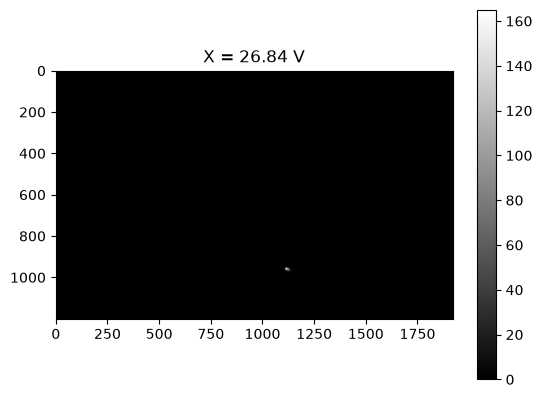

X voltage: 27.338794309701495 V image shape: (1200, 1920)


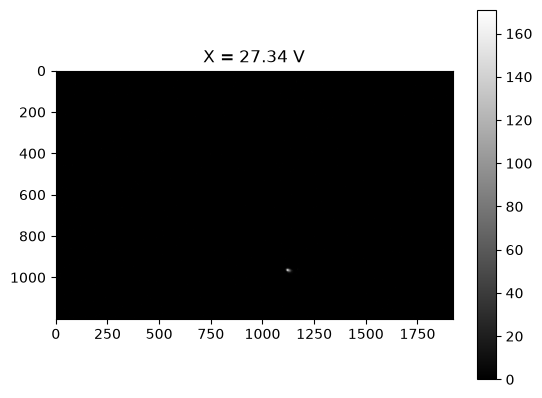

X voltage: 27.838794309701495 V image shape: (1200, 1920)


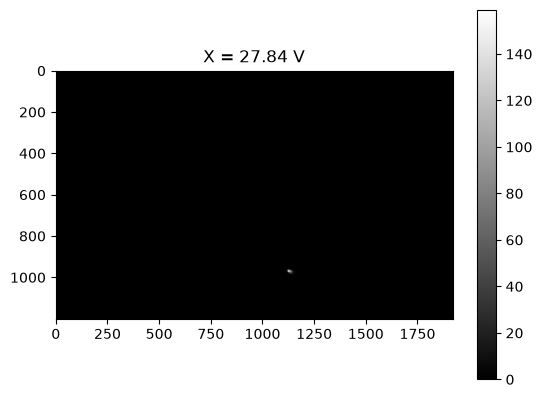

In [9]:
import matplotlib.pyplot as plt

for event in images[-3:]:  # Last three images: the X scan
    print('X voltage:', event['motor_mm'], 'V',
          'image shape:', event['basler_image'].shape)
    plt.figure()
    plt.imshow(event['basler_image'], cmap='gray')
    plt.title(f"X = {event['motor_mm']:.2f} V")
    plt.colorbar()
    plt.show()

## Beam statistics versus KCube position

Analyze the motor scan events already captured in `images` (no new motion). The 0.1 relative threshold selects pixels with intensity at least 10% of each image's peak for the intensity-weighted centroid and RMS beam sizes. Peak and total intensity are measured on the whole nonnegative image, before thresholding; no background subtraction is applied. Beam center and RMS sizes are in camera pixels; the combined size is `sqrt(size_x**2 + size_y**2)`. If backgrounds bias these values, first subtract a measured dark image and/or crop to a beam ROI.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from blop_optics import beam_statistics

relative_threshold = 0.1  # Change to tune rejection of low-level background.
# The original subscriber stored event['data'] dictionaries in acquisition order.
# Select the most recent three motor events (not the first X-voltage scan).
motor_events = [event for event in images if 'motor_mm' in event][-3:]
if len(motor_events) != 3:
    raise ValueError(f'Expected 3 motor scan images, found {len(motor_events)}')

motor_stats = []
for event in motor_events:
    stats = beam_statistics(event['basler_image'], relative_threshold=relative_threshold)
    stats['motor_mm'] = float(event['motor_mm'])
    motor_stats.append(stats)
    print(f"motor={stats['motor_mm']:.4f} mm, peak={stats['peak_intensity']:.1f}, "
          f"total={stats['total_intensity']:.1f}, "
          f"center=({stats['center_x_px']:.2f}, {stats['center_y_px']:.2f}) px, "
          f"RMS=({stats['size_x_px']:.2f}, {stats['size_y_px']:.2f}) px, "
          f"combined={stats['size_quadrature_px']:.2f} px")

motor_stats.sort(key=lambda stats: stats['motor_mm'])
plt.plot([s['motor_mm'] for s in motor_stats],
         [s['size_quadrature_px'] for s in motor_stats], 'o-')
plt.xlabel('KCube position (mm)')
plt.ylabel('Quadrature RMS beam size (pixels)')
plt.title(f'Beam size vs motor position (threshold = {relative_threshold:g} × peak)')
plt.grid(True)
plt.show()

In [ ]:
# Run when done (or before reconnecting); do not run while a scan is active.
camera.close()
motor_driver.close()
piezo_driver.close()